## US15

# Objective

The objective of this analysis is to evaluate the annual profitability evolution of a selected railway station using historical financial data. The goal is to apply key descriptive statistics concepts to summarize, describe, and understand patterns in the station’s financial performance over time. Specifically, the analysis will compute central tendency measures, assess dispersion, identify potential outliers, and provide a graphical representation of the results.

# Theoretical Concepts

The following variables will be used in the analysis:

- **Station**: Represents the name of the selected railway station. This variable is a categorical data point used to distinguish the financial data for each station.

- **Year**: Refers to the year to which the financial data pertains. This variable is essential for understanding the annual trends and performing time-based analysis on the profitability.

- **Revenues**: This is the total annual income generated by the station, typically in million euros. Revenues are crucial for understanding the station's financial performance and are used in the calculation of profits.

- **Expenses**: Refers to the total annual costs associated with the operation of the station, again in million euros. Like revenues, expenses are used to determine the profitability of the station and can influence its overall financial health.

- **Profit**: Calculated as the difference between **Revenues** and **Expenses** for each year, representing the station’s net earnings. The profit is the key focus of this analysis and is used to calculate central tendency measures and dispersion statistics.

### Descriptive Statistics

To analyse the data, the following measures were computed:

## 1. Measures of Central Tendency

- **Mean**: The arithmetic average of the annual profits, calculated as:
  $$
  \bar{x} = \frac{1}{n} \sum_{i=1}^{n} x_i
  $$

- **Median**: The middle value when the profits are sorted. The median is a robust measure of central tendency that is less affected by outliers compared to the mean.

- **Mode**: The most frequent annual profit value. If no value repeats, the mode is considered "None."

## 2. Measures of Dispersion

- **Standard Deviation (Sample)**: Measures the dispersion of the profits around the mean. It is calculated as:
  $$
  s = \sqrt{\frac{1}{n-1} \sum_{i=1}^n (x_i - \bar{x})^2}
  $$

- **Quartiles**: The data is divided into four equal parts:
  - \(Q_1\): 25th percentile (lower quartile),
  - \(Q_2\): 50th percentile (median),
  - \(Q_3\): 75th percentile (upper quartile).



- **Interquartile Range (r_q)**: The range between the first and third quartiles, calculated as:
  $$
  r_q = Q_3 - Q_1.
  $$

- **Outliers**: These are profit values that lie outside the interval:
  $$
  [Q_1 - 1.5 \cdot r_q, \quad Q_3 + 1.5 \cdot r_q].
  $$

## 3. Additional Indicators

- **Most profitable year**: The year with the maximum annual profit.
- **Least profitable year**: The year with the minimum annual profit.

# Graphical Representation

To complement the analysis, a **boxplot** was used to:

- Identify skewness in the distribution;
- Visually locate the median and quartiles;
- Detect outliers.



Descriptive Statistics Table:

+----------------------+------------+
|      Measure         | Value (M€) |
+----------------------+------------+
| Mean                 |  11566.759 |
| Standard Deviation   |  12486.256 |
| Median               |   7564.430 |
| Mode                 |       None |
+----------------------+------------+

Statistical Analysis for station: Berlin

Most profitable year: 2023 → 39684.900 M€
Least profitable year: 2015 → 655.760 M€
Outliers (M€): [39684.899999999994]


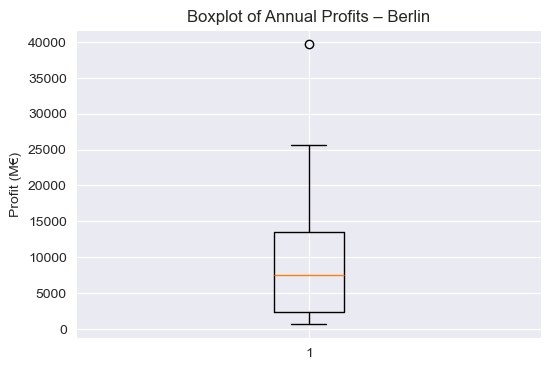

In [6]:
import pandas as pd
import statistics as st
import matplotlib.pyplot as plt

df = pd.read_csv("Stations_Data.csv", sep=';')

for col in df.columns[3:]:
    df[col] = [float(i.replace(",", ".")) for i in df[col].astype(str)]

df["Year"] = df["Year"].astype(int)
df["Profit"] = df["Revenues"] - df["Expenses"]

station = input("Enter the station name: ")
while station not in df["Station"].values:
    print("Error: Station not found. Please enter a valid station name.")
    station = input("Enter the station name: ")

df_s = df[df["Station"] == station]

annual_profit = df_s.groupby("Year")["Profit"].sum()
profits = annual_profit.tolist()

mean_val = st.mean(profits)
median_val = st.median(profits)
std_val = st.stdev(profits)
mode_val = st.mode(profits) if profits.count(st.mode(profits)) > 1 else None

quartiles = st.quantiles(profits, n=4)
Q1, Q2, Q3 = quartiles[0], quartiles[1], quartiles[2]
r_q = Q3 - Q1
lower = Q1 - 1.5 * r_q
upper = Q3 + 1.5 * r_q
outliers = [x for x in profits if x < lower or x > upper]

max_profit = max(profits)
min_profit = min(profits)
best_year = annual_profit.idxmax()
worst_year = annual_profit.idxmin()

print("\nDescriptive Statistics Table:\n")
print("+----------------------+------------+")
print("|      Measure         | Value (M€) |")
print("+----------------------+------------+")
print(f"| {'Mean':<20} | {mean_val:>10.3f} |")
print(f"| {'Standard Deviation':<20} | {std_val:>10.3f} |")
print(f"| {'Median':<20} | {median_val:>10.3f} |")
print(f"| {'Mode':<20} | {mode_val if mode_val is not None else '   None':>10} |")
print("+----------------------+------------+")

print(f"\nStatistical Analysis for station: {station}\n")
print(f"Most profitable year: {best_year} → {max_profit:.3f} M€")
print(f"Least profitable year: {worst_year} → {min_profit:.3f} M€")
print(f"Outliers (M€): {outliers}")

plt.figure(figsize=(6, 4))
plt.boxplot(profits, vert=True)
plt.title(f"Boxplot of Annual Profits – {station}")
plt.ylabel("Profit (M€)")
plt.grid(True)
plt.show()



# Analysis and Interpretation of Results

The annual profits for the selected station were calculated by subtracting the annual expenses from the revenues. Based on this data, several descriptive statistics were applied to characterize the station’s financial behavior over time.

- The **mean** indicates the average annual profit, while the **median** identifies the central value in the ordered list of profits. The **mode**, when it exists, corresponds to the most frequent profit value. These measures provide insight into the general tendency of the data.

- The **standard deviation** quantifies the dispersion of annual profits around the mean, offering a sense of the variability in financial performance. Higher values suggest greater fluctuations between years.

- To detect potential outliers, the **first** and **third quartiles** (Q1 and Q3) were determined, and the **interquartile range (IQR)** was calculated as:
  $$
  r_q = Q3 - Q1.
  $$
  Outliers were defined as profit values outside the interval:
  $$
  [Q1 - 1.5 \times r_q, \; Q3 + 1.5 \times r_q].
  $$

- A **boxplot** was generated to visualize the distribution of profits. This graphical representation highlights the central tendency, spread, and presence of outliers.

- Additionally, the years corresponding to the **maximum** and **minimum profits** were identified, allowing a more contextual interpretation of financial peaks and troughs.

Understanding the annual profit trends is fundamental in transport network planning and optimization. By identifying financially critical years and analyzing variance, transport authorities or developers of the railway simulation can simulate realistic economic behavior of stations over time.

Moreover, these insights can inform future scenario definitions within the simulator, such as setting economic constraints or targets per station, aligning with the strategic goals of the PI (Projecto Integrador).


## US16

## Objective

The objective of this analysis is to perform a comparative evaluation of passenger arrivals across all stations using historical data. The purpose is to understand how passenger traffic is distributed per station, identify patterns and anomalies, and provide visual summaries through boxplots. This will help detect differences in usage and variability between stations, supporting more informed decisions in the simulation.

## Theoretical Concepts

The analysis involves the following variable:

- **Passengers**: Represents the total number of passengers arriving at each station, based on the recorded data points. This is a quantitative continuous variable, which will be analysed for each station individually using descriptive statistics.

### Descriptive Statistics

To analyse and compare the distributions of passenger arrivals, the following measures and graphical tools were applied:

### 1. Boxplot Construction

Boxplots provide a visual summary of the distribution of a dataset using five key statistics:

- **Minimum**: The lowest observed value (excluding outliers)
- **First Quartile (Q₁)**: The 25th percentile — 25% of values fall below this point
- **Median (Q₂)**: The 50th percentile — the central value in the ordered dataset
- **Third Quartile (Q₃)**: The 75th percentile — 75% of values fall below this point
- **Maximum**: The highest observed value (excluding outliers)

### 2. Interquartile Range and Outliers

- **Interquartile Range (r_q)**: Describes the middle 50% of the data and is calculated as:

  $$
  r_q = Q_3 - Q_1
  $$

- **Outliers**: Values that fall outside the interval

  $$
  [Q_1 - 1.5 \cdot r_q,\quad Q_3 + 1.5 \cdot r_q]
  $$

  are considered atypical and are plotted individually in the boxplot.

## Graphical Representation

A boxplot was generated for each station. This type of plot helps to:

- Understand the spread of passenger traffic per station
- Identify stations with higher variability
- Detect possible outliers or unusual traffic spikes
- Visually compare central tendencies and dispersion across multiple stations

Station: Berlin


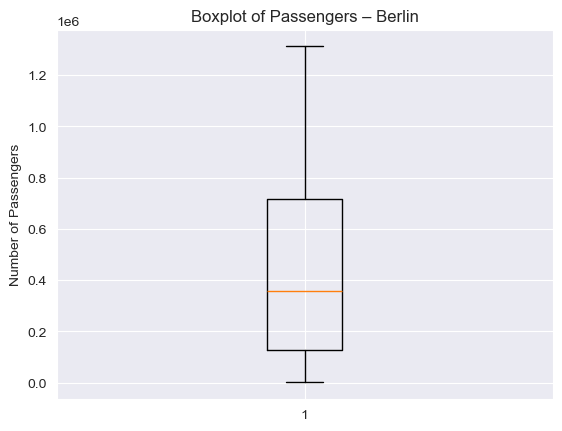

Station: Frankfurt


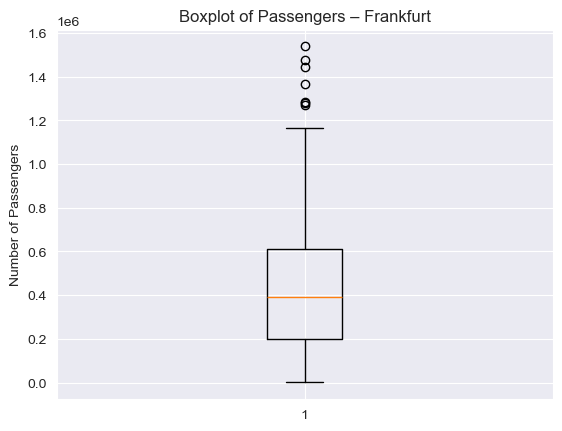

Station: Hamburg


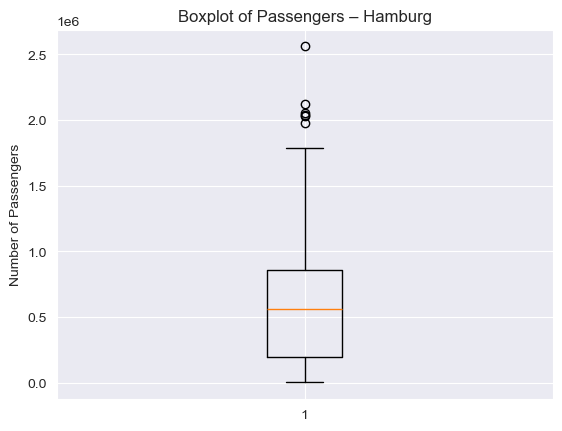

Station: Hannover


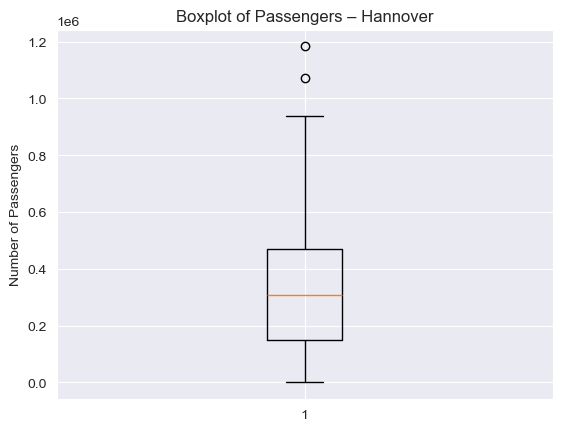

Station: Stuttgart


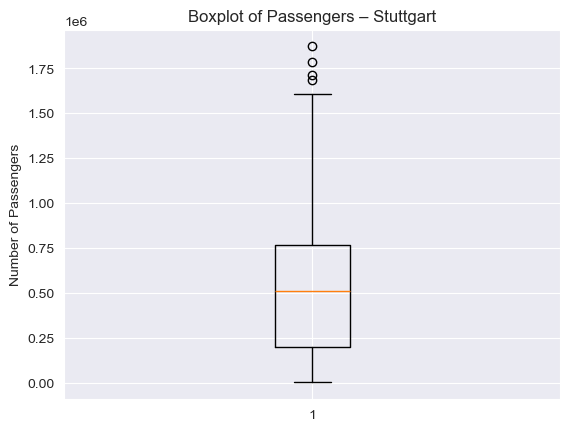

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Stations_Data.csv", sep=';')
df['Passengers'] = df['Passengers'].astype(str).str.replace(',', '.').astype(float)

grouped = df.groupby('Station')

for station_name, df_station in grouped:
    passengers = df_station['Passengers'].tolist()

    print(f"Station: {station_name}")

    plt.boxplot(passengers)
    plt.title(f"Boxplot of Passengers – {station_name}")
    plt.ylabel("Number of Passengers")
    plt.grid(True)
    plt.show()

## Analysis and Interpretation of Results

The boxplots generated for each station allowed a visual comparison of the number of arriving passengers using all available data. Some stations presented higher median values and greater variability, while others had more compact distributions, indicating more consistent passenger volumes.

The presence of outliers in certain stations highlighted unusual variations in passenger arrivals.

This comparative analysis is important to understand which stations consistently handle larger volumes of passengers. Such information can support future decisions within in the scope of PI, such as identifying where it might be strategic to place buildings like cafés, hotels, or other infrastructure at certain stations to increase revenues and profit.

## US17

## Objective

The objective of this analysis is to study the distribution of a specific type of cargo arriving at a selected station using historical simulation data. This analysis aims to detect patterns, variability, and potential anomalies by visualising the data through a histogram.

## Theoretical Concepts

This analysis focuses on the following variable:

- **[Selected Cargo Type]**: Represents the amount of a specific cargo (e.g., *Iron*, *Coffee*, *Passengers*) arriving at a station. This is a **quantitative continuous variable**, typically measured in **tons** (for materials like coal, steel, vegetables, etc.) or as a **number** (for passengers).

### Histogram Construction

A histogram is a graphical representation of data in which:

- **Classes** are displayed on the horizontal axis;
- **Frequencies** are displayed on the vertical axis;
- **Bars** are adjacent and have an area proportional to the frequency of the corresponding class.

In building a histogram for a continuous quantitative variable, each class is an interval of the form \[a, b[ or ]a, b], representing a range of possible values. The following elements must be defined:

- **Class amplitude** (width of each class):

  $$
  \text{Amplitude} = b - a
  $$

- **Class midpoint** (also called mark or characteristic value):

  $$
  \text{Midpoint} = \frac{a + b}{2}
  $$

- **Number of classes (c)** can be estimated using **Sturges' Rule**:

$$
c = \left\lfloor 1 + 3.3 \log_{10}(n) \right\rfloor
$$

where \( n \) is the number of observations and $ \left\lfloor x \right\rfloor $ denotes the integer part of \( x \).

### Interpretation

Histograms are useful for:

- Understanding the shape and spread of the data;
- Identifying central tendencies, skewness, and variability;
- Detecting outliers or irregular patterns.

Available Stations:
1. Stuttgart
2. Frankfurt
3. Hannover
4. Hamburg
5. Berlin

Available Cargo Types:
1. Iron
2. Coal
3. Prata
4. Vegetables
5. Cereals
6. Wool
7. Coffee
8. Cattle
9. Passengers
10. Mail


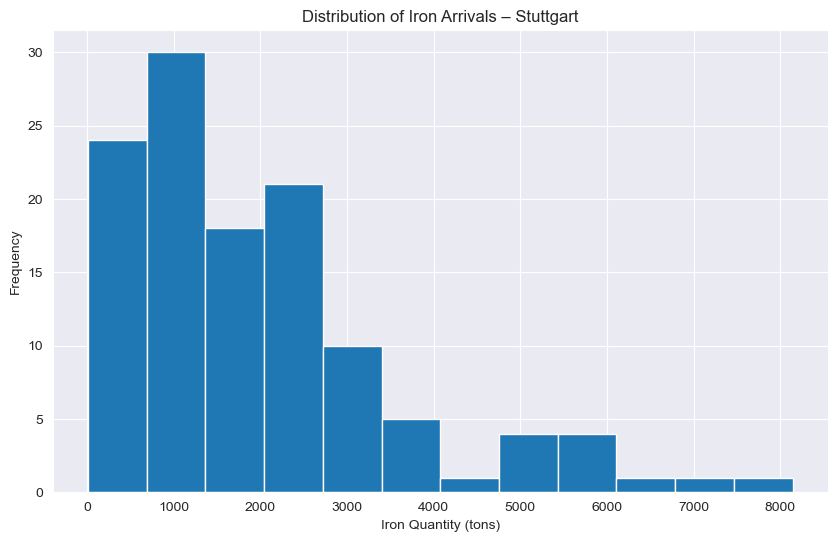

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Stations_Data.csv", sep=';')

cargo_columns = [col for col in df.columns if col not in ['Station', 'Year', 'Month', 'Arrivals', 'Revenues', 'Expenses']]

for col in cargo_columns:
    df[col] = df[col].astype(str).str.replace(',', '.').astype(float)

stations = df['Station'].unique()

print("Available Stations:")
for i, station in enumerate(stations, 1):
    print(f"{i}. {station}")

station_choice = int(input("Choose a station by number: ")) - 1
station_name = stations[station_choice]

print("\nAvailable Cargo Types:")
for i, cargo in enumerate(cargo_columns, 1):
    print(f"{i}. {cargo}")

cargo_choice = int(input("Choose a cargo type by number: ")) - 1
cargo_type = cargo_columns[cargo_choice]

filtered_data = df[df['Station'] == station_name][['Year', 'Month', 'Arrivals', cargo_type]]

plt.figure(figsize=(10, 6))

if cargo_type == "Passengers":
    plt.xlabel(f"Number of {cargo_type}")
else:
    plt.xlabel(f"{cargo_type} Quantity (tons)")

plt.hist(filtered_data[cargo_type], bins='auto')
plt.title(f'Distribution of {cargo_type} Arrivals – {station_name}')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

## Analysis and Interpretation of Results

The histograms generated for each station and cargo type provide a visual representation of the distribution of cargo arrivals across different months and years. These histograms illustrate the frequency of each cargo type’s arrival, but they do not allow direct comparison between different cargo types or stations without further analysis.

In the context of the **Projeto Integrador (PI)** this graphical representation allows the player to better understand how cargo traffic varies by station and cargo type. The histograms help identify which cargo types are being transported more frequently in specific stations.

With this information, the player can optimise transport routes and station management, potentially prioritising cargo types that appear more often in specific stations to enhance operational efficiency within the simulation.


## US18

## Objective

The objective of this analysis is to study the distribution of train arrivals, passengers, and mail across different stations using historical simulation data. This analysis aims to provide insights into how these elements are allocated among the stations, detect patterns, and identify any anomalies in the distribution.

## Theoretical Concepts

This analysis focuses on the following variables:

- **Train Arrivals**: Represents the number of trains arriving at each station. This is a **discrete variable**.

- **Passengers**: Represents the number of passengers arriving at each station. This is a **discrete variable**.

- **Mail**: Represents the tons of mail arriving at each station. This is a **continuous variable**.

### Circular Chart (Pie Chart) Construction

A circular chart (pie chart) is a graphical representation of data in which the data is displayed as sectors or slices of a circle, where the area (and corresponding angle) of each sector is proportional to the frequency of the category it represents. The frequency of each category is calculated as:

- **Absolute Frequency**: The number of observations corresponding to category \(i\), denoted as \(n_i\).

  $$ \sum_{i=1}^{c} n_i = n $$

  where \(n\) is the total number of observations, and \(c\) is the number of categories.

- **Relative Frequency**: The ratio of the absolute frequency of category \(i\) to the total number of observations. The formula is:

  $$ f_i = \frac{n_i}{n} $$

  where \( f_i \) represents the relative frequency of category \(i\), and \(n_i\) is the absolute frequency of category \(i\).

In this analysis, each pie chart represents the distribution of train arrivals, passengers, and mail across different stations. The size of each segment in the chart corresponds to the relative frequency of each station in each category.

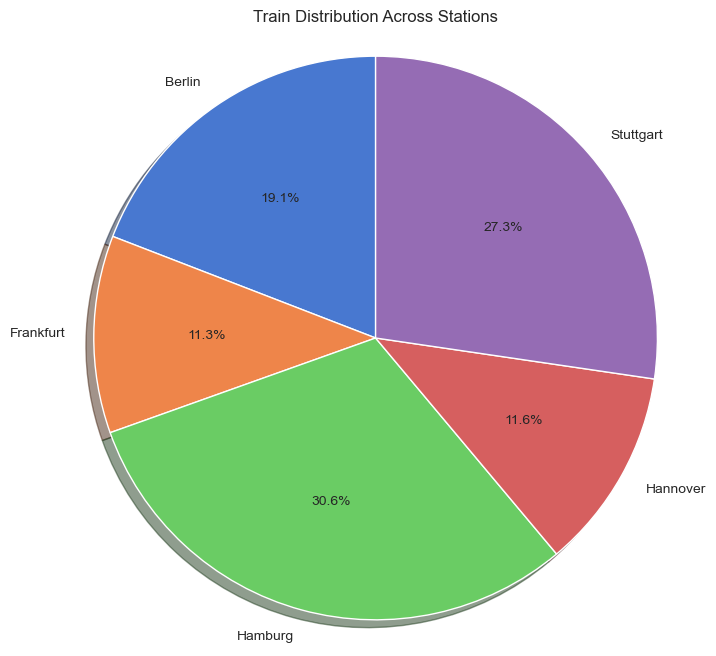

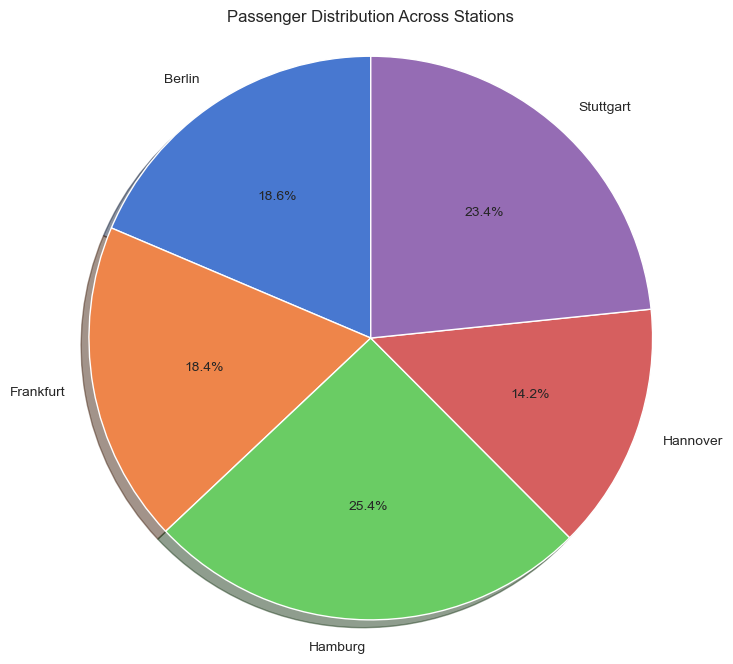

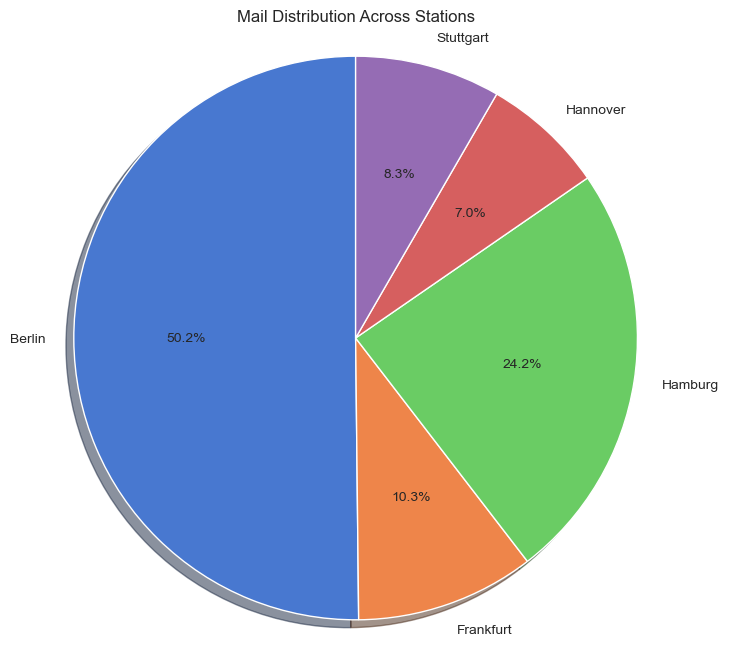

In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("Stations_Data.csv", sep=';')

columns_to_convert = ['Arrivals', 'Passengers', 'Mail']

for col in columns_to_convert:
    if not pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].astype(str)
        df[col] = df[col].str.replace(',', '.')
    df[col] = df[col].astype(float)

station_data = df.groupby('Station')[['Arrivals', 'Passengers', 'Mail']].sum()

def plot_pie_chart(data, column, title):
    plt.figure(figsize=(8, 8))
    plt.pie(data[column], labels=data.index, autopct='%1.1f%%', shadow=True, startangle=90, colors=sns.color_palette('muted'))
    plt.title(title)
    plt.axis('equal')
    plt.show()

plot_pie_chart(station_data, 'Arrivals', 'Train Distribution Across Stations')
plot_pie_chart(station_data, 'Passengers', 'Passenger Distribution Across Stations')
plot_pie_chart(station_data, 'Mail', 'Mail Distribution Across Stations')


## Analysis and Interpretation of Results

The pie charts generated for train arrivals, passengers, and mail provide a clear and visual representation of how these elements are distributed among the stations. Each pie chart shows the relative contribution of each station to the overall total in each category.

- **Train Arrivals**: The pie chart for train arrivals highlights which stations experience the most train traffic. A station with a larger slice represents a higher number of train arrivals. This can inform decisions regarding infrastructure investments, prioritizing stations with higher train traffic for improvements (e.g. more routes connecting that station) or maintenance.

- **Passengers**: The pie chart for passengers illustrates the distribution of passenger traffic across the stations. Stations with larger slices are handling more passengers, which may indicate their importance in the network. This information can be used to allocate resources effectively, such as adding buildings to stations with higher passenger numbers.

- **Mail**: The mail distribution pie chart shows how mail traffic is distributed among stations. Stations with a higher proportion of the mail traffic are crucial for handling postal services. This can influence decisions on where to allocate more storage or processing capacity for mail.

In the context of the **Project Integrator (PI)**, these pie charts provide valuable insights for understanding the network’s performance and optimizing resource allocation. By identifying which stations play key roles in handling trains, passengers, or mail, the analysis helps in making strategic decisions that improve the efficiency and operation of the entire network.

## adicionar contribuçao de cada um e escolher uma estaçao / uma estaçao e tipo de carga e fazer analise para um exemplo concreto